# 01 · Perception evaluation — detection, teams, pitch calibration

What this notebook checks, on **one frame** and then on a **short video segment**:

1. **Detection** of people and ball (default: YOLOX-S COCO through `cv2.dnn`, tiled — no PyTorch).
2. **Team assignment** by shirt colour clustering (KMeans on torso descriptors).
3. **Pitch calibration**: homography image ↔ pitch; reprojected lines must sit on the painted lines.
4. Optional **quantitative scores** against a hand-annotated frame (`data/annotations/*.json`):
   detection precision/recall @ IoU 0.5, team accuracy, landmark reprojection error.

Without a match video yet, it falls back to the real frame of the sibling `offiside_code` project
(AFA stream, Anadia FC – SVA) and that project's calibrated camera model.

In [1]:
import sys, time, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 120)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
from football_eval.config import load_config
from football_eval.detection import build_detector
from football_eval.teams import TeamClassifier
from football_eval.pitch import Pitch, load_calibration, draw_pitch
from football_eval.video import read_frame
from football_eval.evaluation import detection_pr, team_accuracy, load_annotation

source: frame_decision.png | frame (1578, 2930, 3)


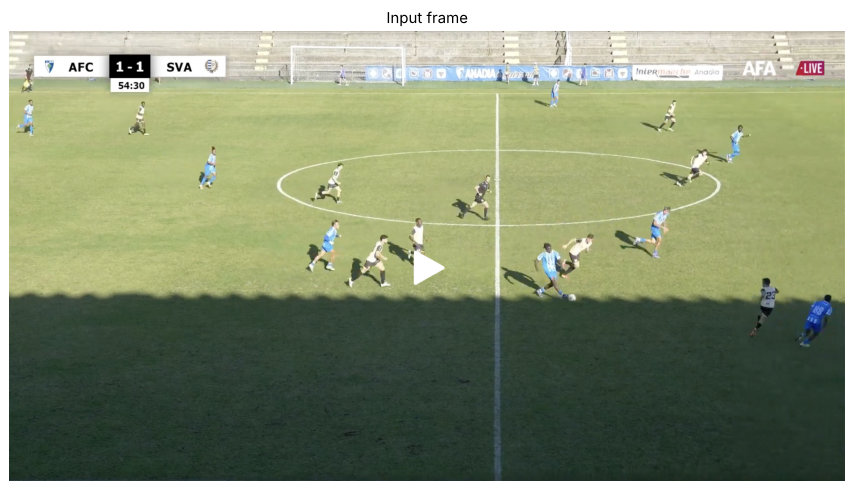

In [2]:
VIDEO = ROOT / "data/videos/match.mp4"            # <- your full-match video
T_FRAME = 600.0                                  # seconds into the video for the single-frame checks
FALLBACK_IMAGE = ROOT.parent / "offiside_code/data/frame_decision.png"
CONFIG = ROOT / "configs/example_anadia.yaml"    # <- your config (calibration file, overlays, team names)
ANNOTATION = None                                # e.g. ROOT / "data/annotations/frame_0600.json"

cfg = load_config(CONFIG)
img = read_frame(str(VIDEO), T_FRAME) if VIDEO.exists() else cv2.imread(str(FALLBACK_IMAGE))
print("source:", (VIDEO if VIDEO.exists() else FALLBACK_IMAGE).name, "| frame", img.shape)
plt.figure(figsize=(12, 6.5)); plt.imshow(img[..., ::-1]); plt.axis("off"); plt.title("Input frame");

## 1 · Detection

24 people, 1 ball candidates in 1.49s (tile=1150)


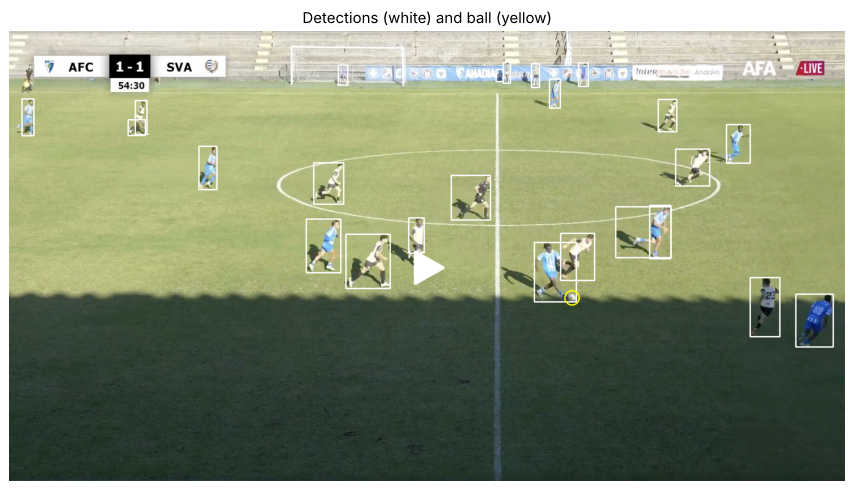

In [3]:
det_model = build_detector(cfg)
t0 = time.time(); det = det_model(img); dt = time.time() - t0
people, balls = det.of("player", "goalkeeper", "referee"), det.of("ball")
print(f"{len(people)} people, {len(balls)} ball candidates in {dt:.2f}s (tile={cfg.detection.tile})")
vis = img.copy()
for (x0, y0, x1, y1), c in zip(people.xyxy.astype(int), people.conf):
    cv2.rectangle(vis, (x0, y0), (x1, y1), (255, 255, 255), 3)
for (x0, y0, x1, y1) in balls.xyxy.astype(int):
    cv2.circle(vis, ((x0 + x1) // 2, (y0 + y1) // 2), 25, (0, 255, 255), 4)
plt.figure(figsize=(12, 6.5)); plt.imshow(vis[..., ::-1]); plt.axis("off"); plt.title("Detections (white) and ball (yellow)");

## 2 · Team assignment (colour clustering)
In a real run the clustering is fitted on ~60 sampled frames and each *track* gets the majority label; here it is fitted on this single frame, which is the hardest case.

        0   1  -1
count  13   9   2


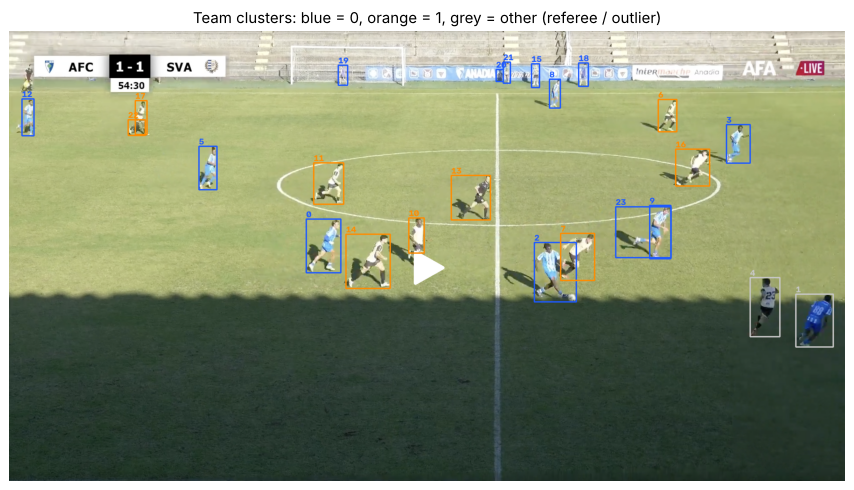

In [4]:
tc = TeamClassifier(cfg.teams.backend)
feats = tc.describe(img, people.xyxy)
ok = [i for i, f in enumerate(feats) if f is not None]
tc.fit(np.array([feats[i] for i in ok]))
labels = np.full(len(people), -1); labels[ok] = tc.predict(np.array([feats[i] for i in ok]))
colors = {0: (255, 90, 30), 1: (0, 140, 255), -1: (200, 200, 200)}
vis = img.copy()
for k, ((x0, y0, x1, y1), l) in enumerate(zip(people.xyxy.astype(int), labels)):
    cv2.rectangle(vis, (x0, y0), (x1, y1), colors[int(l)], 4)
    cv2.putText(vis, str(k), (x0, y0 - 6), 0, 1.0, colors[int(l)], 2)
plt.figure(figsize=(12, 6.5)); plt.imshow(vis[..., ::-1]); plt.axis("off")
plt.title("Team clusters: blue = 0, orange = 1, grey = other (referee / outlier)")
print(pd.Series(labels).value_counts().rename("count").to_frame().T)

## 3 · Pitch calibration (homography)

5 detections are outside the pitch (bench / staff / crowd) and will be ignored


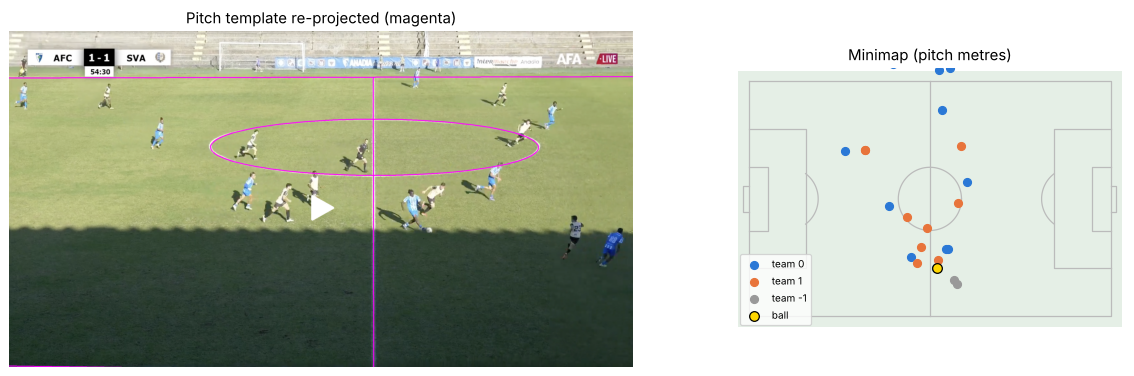

In [5]:
pitch = Pitch(cfg.pitch.length, cfg.pitch.width)
from football_eval.config import resolve_path
H = load_calibration(resolve_path(cfg.pitch.calibration_file), pitch)
vis = img.copy()
for ln in pitch.lines():
    cv2.polylines(vis, [H.to_image(ln).astype(np.int32)], False, (255, 0, 255), 4)
foot = people.foot
xy = H.to_pitch(foot)
fig, ax = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.6, 1]})
ax[0].imshow(vis[..., ::-1]); ax[0].axis("off"); ax[0].set_title("Pitch template re-projected (magenta)")
draw_pitch(ax[1], pitch)
for l in (0, 1, -1):
    m = labels == l
    ax[1].scatter(xy[m, 0], xy[m, 1], s=40, c=["#2a78d6", "#e8743b", "#999999"][l if l >= 0 else 2], label=f"team {l}", zorder=3)
if len(balls):
    bxy = H.to_pitch(balls.foot[:1]); ax[1].scatter(bxy[:, 0], bxy[:, 1], s=60, c="gold", edgecolors="k", zorder=4, label="ball")
ax[1].legend(loc="lower left", fontsize=8); ax[1].set_title("Minimap (pitch metres)")
off = ~pitch.in_pitch(xy[:, 0], xy[:, 1], cfg.pitch.offpitch_margin_m)
print(f"{off.sum()} detections are outside the pitch (bench / staff / crowd) and will be ignored")

## 4 · Quantitative check against a hand-annotated frame
Create an annotation once (start from the template written below, fix it by hand) and set `ANNOTATION`. The scores make detector / clustering / calibration changes comparable.

In [6]:
tmpl = {"image": "frame.png", "boxes": [{"xyxy": [round(float(v), 1) for v in b], "cls": "player", "team": int(l)}
                                       for b, l in zip(people.xyxy, labels)],
        "ball": [round(float(v), 1) for v in balls.foot[0]] if len(balls) else None,
        "landmarks": {"centre": [0, 0], "halfway_top": [0, 0], "circle_top": [0, 0], "circle_bottom": [0, 0]}}
out = ROOT / "data/annotations/template_from_detections.json"; out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(tmpl, indent=1)); print("annotation template ->", out.relative_to(ROOT))

if ANNOTATION:
    ann = load_annotation(ANNOTATION)
    gt_boxes = np.array([b["xyxy"] for b in ann["boxes"]])
    pr = detection_pr(people.xyxy, gt_boxes)
    print({k: v for k, v in pr.items() if k != "matches"})
    ta = team_accuracy([labels[i] for i, _ in pr["matches"]], [ann["boxes"][j]["team"] for _, j in pr["matches"]])
    print("team accuracy:", ta)
    lm = pitch.landmarks()
    names = [n for n, uv in ann["landmarks"].items() if uv != [0, 0]]
    if names:
        print("landmark reprojection error (px):", round(H.reprojection_error([ann["landmarks"][n] for n in names], [lm[n] for n in names]), 1))
else:
    print("No annotation set — skipping the quantitative scores.")

annotation template -> data/annotations/template_from_detections.json
No annotation set — skipping the quantitative scores.


## 5 · Short video segment (tracking + ball + pitch coordinates)
Runs the full perception pipeline on the first `N` analysed frames of the video (if present).

In [7]:
from football_eval.perception import run_perception
N = 300   # analysed frames (30 s at 10 fps)
if VIDEO.exists():
    res = run_perception(str(VIDEO), cfg, max_frames=N)
    tr, ball = res["tracks"], res["ball"]
    print(f"{tr.track_id.nunique()} tracks | mean track length {tr.groupby('track_id').size().mean():.1f} frames | "
          f"ball visible {ball.visible.mean():.0%} | homography {res['frames'].has_h.mean():.0%} of frames")
    fig, ax = plt.subplots(figsize=(9, 6)); draw_pitch(ax, pitch)
    for tm, c in ((0, "#2a78d6"), (1, "#e8743b")):
        q = tr[tr.team == tm]; ax.scatter(q.x, q.y, s=2, c=c, alpha=0.3)
    ax.plot(ball.x, ball.y, c="k", lw=0.8); ax.set_title("Positions over the segment (ball in black)")
else:
    print("No video yet: put your match in data/videos/match.mp4 (or change VIDEO) to run this cell.")

No video yet: put your match in data/videos/match.mp4 (or change VIDEO) to run this cell.


## Reading the results / what to improve next

* **Detection** — COCO YOLOX finds almost every player at this resolution, but also people outside the pitch
  (bench, staff, ball boys): they are removed by the pitch-coordinate filter. The ball is found when it is not
  occluded; a football-fine-tuned detector (YOLO11/RT-DETR trained on football data) is the biggest single upgrade.
* **Teams** — colour clustering separates the two kits well in sunlight, but **shadows** push players to "other"
  and a **dark referee kit** can join the team with dark shorts. Fixes, in order of effort: per-track majority vote
  over many frames (already in the pipeline) → SigLIP embeddings (`teams.backend: siglip`) → a small classifier
  trained on a few hundred labelled crops from your club's matches.
* **Calibration** — for a fixed camera, calibrate once per venue (`scripts/calibrate_points.py`, ≥ 6 well spread
  landmarks). If the operator pans/zooms, use `pitch.homography: flow` with a few anchors, or a pitch-keypoint model.